2.1 — Molecular similarity using RDKit

In [3]:

%pip install -q rdkit


In [4]:

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

# Define molecules using SMILES
molecules = {
    "Aspirin": "CC(=O)Oc1ccccc1C(=O)O",
    "Salicylic Acid": "O=C(O)c1ccccc1O",
    "Paracetamol": "CC(=O)Nc1ccc(O)cc1",
    "Benzene": "c1ccccc1"
}

# Generate Morgan fingerprints
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

fingerprints = {}

for name, smiles in molecules.items():
    mol = Chem.MolFromSmiles(smiles)
    fingerprints[name] = generator.GetFingerprint(mol)

# Compare every molecule against aspirin
aspirin_fp = fingerprints["Aspirin"]

for name, fp in fingerprints.items():
    similarity = DataStructs.TanimotoSimilarity(
        aspirin_fp, fp
    )

    print(
        f"Aspirin vs {name}: {similarity:.3f}"
    )


Aspirin vs Aspirin: 1.000
Aspirin vs Salicylic Acid: 0.448
Aspirin vs Paracetamol: 0.222
Aspirin vs Benzene: 0.125


2.2 — Substructure Searching with RDKit

In [5]:

from rdkit import Chem

# Define molecules
molecules = {
    "Aspirin": "CC(=O)Oc1ccccc1C(=O)O",
    "Salicylic Acid": "O=C(O)c1ccccc1O",
    "Paracetamol": "CC(=O)Nc1ccc(O)cc1",
    "Ethanol": "CCO"
}

# Define benzene as the substructure
benzene_pattern = Chem.MolFromSmarts("c1ccccc1")

# Check each molecule
for name, smiles in molecules.items():
    mol = Chem.MolFromSmiles(smiles)

    has_benzene = mol.HasSubstructMatch(
        benzene_pattern
    )

    print(name, "contains benzene ring:", has_benzene)


Aspirin contains benzene ring: True
Salicylic Acid contains benzene ring: True
Paracetamol contains benzene ring: True
Ethanol contains benzene ring: False


2.3 — Understand SMILES vs SMARTS

In [6]:
benzene_pattern = Chem.MolFromSmarts("c1ccccc1")

In [7]:
mol.HasSubstructMatch(benzene_pattern)

False

2.4 — Identify multiple functional groups

In [8]:

from rdkit import Chem

# Define SMARTS patterns
functional_groups = {
    "Carboxylic Acid": "[CX3](=O)[OX2H1]",
    "Hydroxyl": "[OX2H]",
    "Amide": "[NX3][CX3](=[OX1])"
}

# Define molecules
molecules = {
    "Aspirin": "CC(=O)Oc1ccccc1C(=O)O",
    "Paracetamol": "CC(=O)Nc1ccc(O)cc1",
    "Ethanol": "CCO"
}

# Search each molecule
for name, smiles in molecules.items():
    mol = Chem.MolFromSmiles(smiles)

    print("\nMolecule:", name)

    for group_name, smarts in functional_groups.items():
        pattern = Chem.MolFromSmarts(smarts)

        result = mol.HasSubstructMatch(pattern)

        print(group_name, ":", result)



Molecule: Aspirin
Carboxylic Acid : True
Hydroxyl : True
Amide : False

Molecule: Paracetamol
Carboxylic Acid : False
Hydroxyl : True
Amide : True

Molecule: Ethanol
Carboxylic Acid : False
Hydroxyl : True
Amide : False


2.5 — Introduction to Bemis–Murcko scaffolds

In [9]:

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

molecules = {
    "Aspirin": "CC(=O)Oc1ccccc1C(=O)O",
    "Salicylic Acid": "O=C(O)c1ccccc1O",
    "Paracetamol": "CC(=O)Nc1ccc(O)cc1",
    "Benzene": "c1ccccc1"
}

for name, smiles in molecules.items():

    mol = Chem.MolFromSmiles(smiles)

    scaffold = MurckoScaffold.GetScaffoldForMol(mol)

    scaffold_smiles = Chem.MolToSmiles(scaffold)

    print(name)
    print("Original SMILES:", smiles)
    print("Scaffold SMILES:", scaffold_smiles)
    print("-----------------------")


Aspirin
Original SMILES: CC(=O)Oc1ccccc1C(=O)O
Scaffold SMILES: c1ccccc1
-----------------------
Salicylic Acid
Original SMILES: O=C(O)c1ccccc1O
Scaffold SMILES: c1ccccc1
-----------------------
Paracetamol
Original SMILES: CC(=O)Nc1ccc(O)cc1
Scaffold SMILES: c1ccccc1
-----------------------
Benzene
Original SMILES: c1ccccc1
Scaffold SMILES: c1ccccc1
-----------------------


2.6 — Compare different molecular scaffolds

Benzene : c1ccccc1
Pyridine : c1ccncc1
Cyclohexane : C1CCCCC1
Naphthalene : c1ccc2ccccc2c1


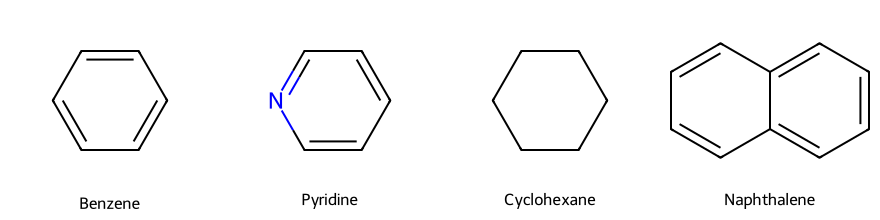

In [10]:

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import Draw

molecules = {
    "Benzene": "c1ccccc1",
    "Pyridine": "c1ccncc1",
    "Cyclohexane": "C1CCCCC1",
    "Naphthalene": "c1ccc2ccccc2c1"
}

scaffolds = []

for name, smiles in molecules.items():
    mol = Chem.MolFromSmiles(smiles)

    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    scaffolds.append(scaffold)

    print(name, ":", Chem.MolToSmiles(scaffold))

# Visualize the different scaffolds
image = Draw.MolsToGridImage(
    scaffolds,
    molsPerRow=4,
    subImgSize=(220, 220),
    legends=list(molecules.keys())
)

display(image)


2.6 — Conceptual checkpoint

2.7 — Calculate scaffold diversity

In [11]:

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
import pandas as pd

# Small example dataset
molecules = {
    "Aspirin": "CC(=O)Oc1ccccc1C(=O)O",
    "Salicylic Acid": "O=C(O)c1ccccc1O",
    "Paracetamol": "CC(=O)Nc1ccc(O)cc1",
    "Benzene": "c1ccccc1",
    "Pyridine": "c1ccncc1",
    "Cyclohexane": "C1CCCCC1",
    "Naphthalene": "c1ccc2ccccc2c1"
}

results = []

for name, smiles in molecules.items():
    mol = Chem.MolFromSmiles(smiles)

    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    scaffold_smiles = Chem.MolToSmiles(scaffold)

    results.append({
        "Molecule": name,
        "Scaffold": scaffold_smiles
    })

scaffold_df = pd.DataFrame(results)

display(scaffold_df)

print("Total molecules:", len(scaffold_df))
print("Unique scaffolds:", scaffold_df["Scaffold"].nunique())


,Molecule,Scaffold
0,Aspirin,c1ccccc1
1,Salicylic Acid,c1ccccc1
2,Paracetamol,c1ccccc1
3,Benzene,c1ccccc1
4,Pyridine,c1ccncc1
5,Cyclohexane,C1CCCCC1
6,Naphthalene,c1ccc2ccccc2c1


Total molecules: 7
Unique scaffolds: 4


2.8 — Select a biological target

In [12]:

%pip install -q chembl_webresource_client


In [13]:

from chembl_webresource_client.new_client import new_client

print("ChEMBL client imported successfully!")


/usr/local/lib/python3.13/dist-packages/chembl_webresource_client/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __version__ = __import__('pkg_resources').get_distribution('chembl_webresource_client').version


ChEMBL client imported successfully!


In [14]:

from chembl_webresource_client.new_client import new_client

# Search ChEMBL for EGFR targets
target_client = new_client.target

targets = target_client.filter(
    target_synonym__icontains="EGFR"
).only(
    "target_chembl_id",
    "pref_name",
    "organism",
    "target_type"
)[:10]

# Display the results
for target in targets:
    print(
        target["target_chembl_id"],
        "|", target["pref_name"],
        "|", target["organism"],
        "|", target["target_type"]
    )


CHEMBL203 | Epidermal growth factor receptor | Homo sapiens | SINGLE PROTEIN
CHEMBL1868 | Vascular endothelial growth factor receptor 1 | Homo sapiens | SINGLE PROTEIN
CHEMBL279 | Vascular endothelial growth factor receptor 2 | Homo sapiens | SINGLE PROTEIN
CHEMBL1955 | Vascular endothelial growth factor receptor 3 | Homo sapiens | SINGLE PROTEIN
CHEMBL3608 | Epidermal growth factor receptor | Mus musculus | SINGLE PROTEIN
CHEMBL3516 | Vascular endothelial growth factor receptor 1 | Mus musculus | SINGLE PROTEIN
CHEMBL3337 | Vascular endothelial growth factor receptor 2 | Mus musculus | SINGLE PROTEIN
CHEMBL4758 | Vascular endothelial growth factor receptor 3 | Mus musculus | SINGLE PROTEIN
CHEMBL2095227 | Vascular endothelial growth factor receptor | Homo sapiens | PROTEIN FAMILY
CHEMBL2111409 | Vascular endothelial growth factor receptor 2 and 3 (KDR and Flt-4) | Homo sapiens | SELECTIVITY GROUP


2.9 — Retrieve experimental EGFR bioactivity data

In [15]:

import pandas as pd
from chembl_webresource_client.new_client import new_client

# Connect to ChEMBL activity database
activity_client = new_client.activity

# Retrieve EGFR IC50 measurements in nM
activities = activity_client.filter(
    target_chembl_id="CHEMBL203",
    standard_type="IC50",
    standard_units="nM",
    standard_relation="="
).only(
    "molecule_chembl_id",
    "canonical_smiles",
    "standard_value",
    "standard_type",
    "standard_units",
    "assay_chembl_id"
)[:100]

# Convert to a DataFrame
egfr_df = pd.DataFrame(list(activities))

# Display the retrieved records
print("Activity records retrieved:", len(egfr_df))
print("Dataset columns:", egfr_df.columns.tolist())

display(egfr_df.head())


Activity records retrieved: 100
Dataset columns: ['assay_chembl_id', 'canonical_smiles', 'molecule_chembl_id', 'standard_type', 'standard_units', 'standard_value', 'type', 'units', 'value']


,assay_chembl_id,canonical_smiles,molecule_chembl_id,standard_type,standard_units,standard_value,type,units,value
0,None,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL68920,IC50,nM,41.0,IC50,uM,0.041
1,None,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL68920,IC50,nM,300.0,IC50,uM,0.3
2,None,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL68920,IC50,nM,7820.0,IC50,uM,7.82
3,None,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,CHEMBL69960,IC50,nM,170.0,IC50,uM,0.17
4,None,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,CHEMBL69960,IC50,nM,40.0,IC50,uM,0.04


2.10 — Clean and inspect EGFR bioactivity measurements

In [16]:

import pandas as pd

# Work on a copy of the downloaded records
egfr_clean = egfr_df.copy()

# Convert IC50 values into numeric form
egfr_clean["IC50_nM"] = pd.to_numeric(
    egfr_clean["standard_value"],
    errors="coerce"
)

# Inspect data quality before cleaning
print("Original activity records:", len(egfr_clean))
print("Missing SMILES:", egfr_clean["canonical_smiles"].isna().sum())
print("Missing or nonnumeric IC50:", egfr_clean["IC50_nM"].isna().sum())
print("Non-positive IC50:", (egfr_clean["IC50_nM"] <= 0).sum())
print("Unique molecule IDs:", egfr_clean["molecule_chembl_id"].nunique())

# Remove records with missing or invalid values
egfr_clean = egfr_clean.dropna(
    subset=["canonical_smiles", "IC50_nM"]
).copy()

egfr_clean = egfr_clean[
    egfr_clean["IC50_nM"] > 0
].copy()

print("---------------------------")
print("Cleaned activity records:", len(egfr_clean))
print("Unique molecules remaining:",
      egfr_clean["molecule_chembl_id"].nunique())

display(
    egfr_clean[
        ["molecule_chembl_id", "assay_chembl_id", "IC50_nM"]
    ].head()
)


Original activity records: 100
Missing SMILES: 0
Missing or nonnumeric IC50: 0
Non-positive IC50: 0
Unique molecule IDs: 82
---------------------------
Cleaned activity records: 100
Unique molecules remaining: 82


,molecule_chembl_id,assay_chembl_id,IC50_nM
0,CHEMBL68920,None,41.0
1,CHEMBL68920,None,300.0
2,CHEMBL68920,None,7820.0
3,CHEMBL69960,None,170.0
4,CHEMBL69960,None,40.0


2.11 — Investigating repeated IC50 measurements

In [17]:

# Count measurements per molecule
measurement_counts = (
    egfr_clean.groupby("molecule_chembl_id")
    .size()
    .sort_values(ascending=False)
)

print("Molecules with repeated measurements:",
      (measurement_counts > 1).sum())

print("\nTop 10 measurement counts:")
print(measurement_counts.head(10))

# Select one molecule with multiple IC50 measurements
example = egfr_clean[
    egfr_clean["molecule_chembl_id"] == "CHEMBL68920"
]

print("\nCHEMBL68920 measurements:")
display(example[
    ["molecule_chembl_id", "assay_chembl_id", "IC50_nM"]
])

print("Minimum IC50:", example["IC50_nM"].min())
print("Maximum IC50:", example["IC50_nM"].max())

print("Fold difference:",
      round(
          example["IC50_nM"].max() /
          example["IC50_nM"].min(),
          2
      ))


Molecules with repeated measurements: 10

Top 10 measurement counts:
molecule_chembl_id
CHEMBL305246    3
CHEMBL68920     3
CHEMBL69358     3
CHEMBL69629     3
CHEMBL69960     3
CHEMBL69966     3
CHEMBL66570     3
CHEMBL65848     3
CHEMBL67003     2
CHEMBL67057     2
dtype: int64

CHEMBL68920 measurements:


,molecule_chembl_id,assay_chembl_id,IC50_nM
0,CHEMBL68920,None,41.0
1,CHEMBL68920,None,300.0
2,CHEMBL68920,None,7820.0


Minimum IC50: 41.0
Maximum IC50: 7820.0
Fold difference: 190.73


2.12 — Check assay metadata availability

In [18]:

# Investigate the missing assay identifiers

print("Total activity records:", len(egfr_clean))

print(
    "Missing assay IDs:",
    egfr_clean["assay_chembl_id"].isna().sum()
)

print(
    "Available assay IDs:",
    egfr_clean["assay_chembl_id"].notna().sum()
)

print(
    "Unique available assay IDs:",
    egfr_clean["assay_chembl_id"].nunique()
)

# Display the relevant records
display(
    egfr_clean[
        [
            "molecule_chembl_id",
            "assay_chembl_id",
            "IC50_nM"
        ]
    ].head(10)
)


Total activity records: 100
Missing assay IDs: 20
Available assay IDs: 80
Unique available assay IDs: 6


,molecule_chembl_id,assay_chembl_id,IC50_nM
0,CHEMBL68920,None,41.0
1,CHEMBL68920,None,300.0
2,CHEMBL68920,None,7820.0
3,CHEMBL69960,None,170.0
4,CHEMBL69960,None,40.0
5,CHEMBL69960,None,440.0
6,CHEMBL137635,None,9300.0
7,CHEMBL306988,None,500000.0
8,CHEMBL66879,None,3000000.0
9,CHEMBL77085,None,96000.0


2.13 — Retrieve EGFR Activity Records and Assay IDs

In [21]:

from chembl_webresource_client.new_client import new_client
import pandas as pd

# Connect to ChEMBL activity database
activity_client = new_client.activity

# Retrieve experimental records for one molecule
records = list(
    activity_client.filter(
        molecule_chembl_id="CHEMBL68920",
        target_chembl_id="CHEMBL203",
        standard_type="IC50",
        standard_units="nM"
    ).only(
        "activity_id",
        "assay_chembl_id",
        "molecule_chembl_id",
        "standard_value",
        "standard_relation"
    )[:20]
)

# Convert records into a table
assay_check = pd.DataFrame(records)

print("Records retrieved:", len(assay_check))
display(assay_check)


Records retrieved: 3


,activity_id,assay_chembl_id,molecule_chembl_id,relation,standard_relation,standard_value,value
0,32260,CHEMBL674637,CHEMBL68920,=,=,41.0,0.041
1,32263,CHEMBL621151,CHEMBL68920,=,=,300.0,0.3
2,32265,CHEMBL615325,CHEMBL68920,=,=,7820.0,7.82


2.14 — Retrieve Experimental Assay Information

In [22]:

from chembl_webresource_client.new_client import new_client
import pandas as pd

# Three assay IDs from our EGFR activity data
assay_ids = [
    "CHEMBL674637",
    "CHEMBL621151",
    "CHEMBL615325"
]

# Connect to the ChEMBL assay database
assay_client = new_client.assay

assay_records = []

# Retrieve information about each assay
for assay_id in assay_ids:

    record = assay_client.get(assay_id)

    assay_records.append({
        "Assay ID": assay_id,
        "Assay Type": record.get("assay_type"),
        "Description": record.get("description"),
        "Confidence Score": record.get("confidence_score")
    })

# Convert results into a table
assay_df = pd.DataFrame(assay_records)

display(assay_df)


,Assay ID,Assay Type,Description,Confidence Score
0,CHEMBL674637,B,Inhibitory activity towards tyrosine phosphory...,8
1,CHEMBL621151,F,Inhibition of autophosphorylation of human epi...,9
2,CHEMBL615325,F,Inhibition of ligand-induced proliferation in ...,9


A ChEMBL assay confidence score indicates how confidently ChEMBL can assign an experimental assay to a particular biological target.

A ChEMBL confidence score of 9 means the assay has been directly assigned to a specific single-protein target.

It does not mean the IC50 is 90% accurate or that the compound has a 90% probability of becoming a successful drug.

2.15 — Compare Experimental Assay Conditions

In [23]:

# Print the complete assay descriptions

for _, row in assay_df.iterrows():

    print("=" * 60)

    print("Assay ID:", row["Assay ID"])

    print("Assay Type:", row["Assay Type"])

    print("Confidence Score:", row["Confidence Score"])

    print("Full Description:")
    print(row["Description"])

    print("=" * 60)
    print()


Assay ID: CHEMBL674637
Assay Type: B
Confidence Score: 8
Full Description:
Inhibitory activity towards tyrosine phosphorylation for the epidermal growth factor-receptor kinase

Assay ID: CHEMBL621151
Assay Type: F
Confidence Score: 9
Full Description:
Inhibition of autophosphorylation of human epidermal growth factor-receptor (EGF-R) expressed in A431 cells

Assay ID: CHEMBL615325
Assay Type: F
Confidence Score: 9
Full Description:
Inhibition of ligand-induced proliferation in human EGF-R Kinase expressing 3T3 cells



2.16 — Define criteria for active EGFR molecules

In [24]:

# Inspect available activity metadata before filtering

columns_to_check = [
    "assay_chembl_id",
    "standard_type",
    "standard_units",
    "standard_relation",
    "IC50_nM"
]

for column in columns_to_check:
    print(column, ":", column in egfr_clean.columns)

print("\nTotal records:", len(egfr_clean))

print("\nIC50 values <= 1000 nM:",
      (egfr_clean["IC50_nM"] <= 1000).sum())

print("\nIC50 values > 1000 nM:",
      (egfr_clean["IC50_nM"] > 1000).sum())

print("\nAvailable assay IDs:")
print(egfr_clean["assay_chembl_id"].value_counts())


assay_chembl_id : True
standard_type : True
standard_units : True
standard_relation : False
IC50_nM : True

Total records: 100

IC50 values <= 1000 nM: 41

IC50 values > 1000 nM: 59

Available assay IDs:
assay_chembl_id
CHEMBL674643    37
CHEMBL677833    15
CHEMBL674637    13
CHEMBL621151     8
CHEMBL615325     6
CHEMBL679674     1
Name: count, dtype: int64


2.17 — Verify the IC50 measurement relation

In [25]:

# Check relation information in the original activity dataset

print("Original dataset columns:")
print(egfr_df.columns.tolist())

# Inspect available relation columns
relation_columns = [
    col for col in egfr_df.columns
    if "relation" in col.lower()
]

print("\nRelation columns:", relation_columns)

for col in relation_columns:
    print("\n", col)
    print(egfr_df[col].value_counts(dropna=False))

# Check whether activity IDs are available
print("\nActivity ID available:",
      "activity_id" in egfr_df.columns)


Original dataset columns:
['assay_chembl_id', 'canonical_smiles', 'molecule_chembl_id', 'standard_type', 'standard_units', 'standard_value', 'type', 'units', 'value']

Relation columns: []

Activity ID available: False


2.18 — Retrieve complete activity metadata

In [26]:

import pandas as pd
from chembl_webresource_client.new_client import new_client

activity_client = new_client.activity

# Retrieve EGFR activity records with important metadata
updated_records = list(
    activity_client.filter(
        target_chembl_id="CHEMBL203",
        standard_type="IC50",
        standard_units="nM",
        standard_relation="="
    ).only(
        "activity_id",
        "assay_chembl_id",
        "molecule_chembl_id",
        "canonical_smiles",
        "standard_value",
        "standard_type",
        "standard_units",
        "standard_relation"
    )[:100]
)

egfr_updated = pd.DataFrame(updated_records)

# Verify retrieved data
print("Records retrieved:", len(egfr_updated))
print("Dataset columns:", egfr_updated.columns.tolist())

print("\nMeasurement relations:")
print(
    egfr_updated["standard_relation"].value_counts(
        dropna=False
    )
)

print("\nMissing assay IDs:",
      egfr_updated["assay_chembl_id"].isna().sum())

print("Missing activity IDs:",
      egfr_updated["activity_id"].isna().sum())

display(egfr_updated.head())


Records retrieved: 100
Dataset columns: ['activity_id', 'assay_chembl_id', 'canonical_smiles', 'molecule_chembl_id', 'relation', 'standard_relation', 'standard_type', 'standard_units', 'standard_value', 'type', 'units', 'value']

Measurement relations:
standard_relation
=    100
Name: count, dtype: int64

Missing assay IDs: 0
Missing activity IDs: 0


,activity_id,assay_chembl_id,canonical_smiles,molecule_chembl_id,relation,standard_relation,standard_type,standard_units,standard_value,type,units,value
0,32260,CHEMBL674637,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL68920,=,=,IC50,nM,41.0,IC50,uM,0.041
1,32263,CHEMBL621151,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL68920,=,=,IC50,nM,300.0,IC50,uM,0.3
2,32265,CHEMBL615325,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL68920,=,=,IC50,nM,7820.0,IC50,uM,7.82
3,32267,CHEMBL674637,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,CHEMBL69960,=,=,IC50,nM,170.0,IC50,uM,0.17
4,32270,CHEMBL621151,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,CHEMBL69960,=,=,IC50,nM,40.0,IC50,uM,0.04


2.19 — Verify and prepare the corrected dataset

In [27]:

import pandas as pd

# Convert updated IC50 measurements to numeric values
egfr_updated["IC50_nM"] = pd.to_numeric(
    egfr_updated["standard_value"],
    errors="coerce"
)

# Compare old and updated datasets
comparison_columns = [
    "molecule_chembl_id",
    "canonical_smiles",
    "IC50_nM"
]

old_records = egfr_clean[
    comparison_columns
].sort_values(comparison_columns).reset_index(drop=True)

new_records = egfr_updated[
    comparison_columns
].sort_values(comparison_columns).reset_index(drop=True)

print("Old record count:", len(old_records))
print("Updated record count:", len(new_records))

print(
    "Datasets contain the same molecule/IC50 records:",
    old_records.equals(new_records)
)

print(
    "Updated unique molecules:",
    egfr_updated["molecule_chembl_id"].nunique()
)

print(
    "Missing updated IC50 values:",
    egfr_updated["IC50_nM"].isna().sum()
)

print(
    "Non-positive updated IC50:",
    (egfr_updated["IC50_nM"] <= 0).sum()
)


Old record count: 100
Updated record count: 100
Datasets contain the same molecule/IC50 records: True
Updated unique molecules: 82
Missing updated IC50 values: 0
Non-positive updated IC50: 0


2.20 — Analyze IC50 Activity by Assay

In [28]:

# Prepare a copy of the corrected EGFR dataset
egfr_analysis = egfr_updated.copy()

# Define the educational activity threshold
egfr_analysis["Active"] = (
    egfr_analysis["IC50_nM"] <= 1000
)

# Summarize measurements within each assay
assay_summary = (
    egfr_analysis
    .groupby("assay_chembl_id")
    .agg(
        Total_Records=("activity_id", "count"),
        Unique_Molecules=("molecule_chembl_id", "nunique"),
        Active_Records=("Active", "sum"),
        Minimum_IC50=("IC50_nM", "min"),
        Median_IC50=("IC50_nM", "median"),
        Maximum_IC50=("IC50_nM", "max")
    )
    .reset_index()
)

print("Total activity records:", len(egfr_analysis))
print("Records meeting IC50 <= 1000 nM:",
      egfr_analysis["Active"].sum())

print("Number of assays:",
      egfr_analysis["assay_chembl_id"].nunique())

display(assay_summary)


Total activity records: 100
Records meeting IC50 <= 1000 nM: 41
Number of assays: 6


,assay_chembl_id,Total_Records,Unique_Molecules,Active_Records,Minimum_IC50,Median_IC50,Maximum_IC50
0,CHEMBL615325,8,8,3,440.00,1670.0,7820.0
1,CHEMBL621151,10,10,9,40.00,100.0,5000.0
2,CHEMBL674637,17,17,15,0.45,18.0,5310.0
3,CHEMBL674643,48,48,2,125.00,350000.0,6500000.0
4,CHEMBL677833,16,16,12,11.00,219.0,13350.0
5,CHEMBL679674,1,1,0,3200.00,3200.0,3200.0


2.21 — Investigate all six EGFR assays

In [29]:

from chembl_webresource_client.new_client import new_client
import pandas as pd

# Get the six assay IDs from our dataset
assay_ids = sorted(
    egfr_analysis["assay_chembl_id"].unique()
)

assay_client = new_client.assay
assay_details = []

# Retrieve information for each assay
for assay_id in assay_ids:
    record = assay_client.get(assay_id)

    assay_details.append({
        "Assay ID": assay_id,
        "Assay Type": record.get("assay_type"),
        "Confidence Score": record.get("confidence_score"),
        "Description": record.get("description")
    })

all_assays_df = pd.DataFrame(assay_details)

# Display complete descriptions
for _, row in all_assays_df.iterrows():
    print("=" * 60)
    print("Assay ID:", row["Assay ID"])
    print("Assay Type:", row["Assay Type"])
    print("Confidence:", row["Confidence Score"])
    print("Description:", row["Description"])
    print()


Assay ID: CHEMBL615325
Assay Type: F
Confidence: 9
Description: Inhibition of ligand-induced proliferation in human EGF-R Kinase expressing 3T3 cells

Assay ID: CHEMBL621151
Assay Type: F
Confidence: 9
Description: Inhibition of autophosphorylation of human epidermal growth factor-receptor (EGF-R) expressed in A431 cells

Assay ID: CHEMBL674637
Assay Type: B
Confidence: 8
Description: Inhibitory activity towards tyrosine phosphorylation for the epidermal growth factor-receptor kinase

Assay ID: CHEMBL674643
Assay Type: B
Confidence: 8
Description: Inhibitory concentration of EGF dependent autophosphorylation of epidermal growth factor receptor kinase

Assay ID: CHEMBL677833
Assay Type: B
Confidence: 8
Description: In vitro inhibition of Epidermal growth factor receptor tyrosine kinase isolated from A431 (human carcinoma).

Assay ID: CHEMBL679674
Assay Type: B
Confidence: 8
Description: Inhibition of Epidermal growth factor receptor



2.22 — Select the EGFR kinase inhibition assay

In [30]:

# Select one EGFR kinase inhibition assay
selected_assay = "CHEMBL677833"

egfr_selected = egfr_analysis[
    egfr_analysis["assay_chembl_id"] == selected_assay
].copy()

# Verify the selected records
print("Selected assay:", selected_assay)
print("Total records:", len(egfr_selected))

print("Unique molecule IDs:",
      egfr_selected["molecule_chembl_id"].nunique())

print("IC50 <= 1000 nM:",
      (egfr_selected["IC50_nM"] <= 1000).sum())

print("IC50 > 1000 nM:",
      (egfr_selected["IC50_nM"] > 1000).sum())

print("Missing SMILES:",
      egfr_selected["canonical_smiles"].isna().sum())

display(
    egfr_selected[
        [
            "activity_id",
            "molecule_chembl_id",
            "canonical_smiles",
            "IC50_nM"
        ]
    ].head()
)


Selected assay: CHEMBL677833
Total records: 16
Unique molecule IDs: 16
IC50 <= 1000 nM: 12
IC50 > 1000 nM: 4
Missing SMILES: 0


,activity_id,molecule_chembl_id,canonical_smiles,IC50_nM
6,32680,CHEMBL137635,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,9300.0
21,37510,CHEMBL135592,C/N=N/Nc1ccc2ncnc(N(C)c3ccccc3)c2c1,8000.0
27,42300,CHEMBL136491,CN(C)/N=N/c1ccc2ncnc(Nc3cccc(Cl)c3)c2c1,14.0
29,44685,CHEMBL336113,Cc1cccc(Nc2ncnc3ccc(N)cc23)c1,1000.0
30,44690,CHEMBL133024,C/N=N/Nc1ccc2ncnc(Nc3cccc(Cl)c3)c2c1,100.0


2.23 — Extract active EGFR molecules

In [31]:

# Select compounds meeting our activity threshold
egfr_active = egfr_selected[
    egfr_selected["IC50_nM"] <= 1000
].copy()

# Inspect the active compound dataset
print("Selected assay:", selected_assay)

print("Active records:", len(egfr_active))

print(
    "Unique active molecules:",
    egfr_active["molecule_chembl_id"].nunique()
)

print(
    "Minimum IC50:",
    egfr_active["IC50_nM"].min()
)

print(
    "Maximum IC50:",
    egfr_active["IC50_nM"].max()
)

# Display active compounds
display(
    egfr_active[
        [
            "molecule_chembl_id",
            "canonical_smiles",
            "IC50_nM"
        ]
    ].sort_values("IC50_nM")
)


Selected assay: CHEMBL677833
Active records: 12
Unique active molecules: 12
Minimum IC50: 11.0
Maximum IC50: 1000.0


,molecule_chembl_id,canonical_smiles,IC50_nM
79,CHEMBL134312,CN(C)/N=N/c1ccc2ncnc(Nc3cccc(Br)c3)c2c1,11.0
27,CHEMBL136491,CN(C)/N=N/c1ccc2ncnc(Nc3cccc(Cl)c3)c2c1,14.0
96,CHEMBL137617,C/N=N/Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1,39.0
70,CHEMBL52765,Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1,44.0
35,CHEMBL137364,Brc1cccc(Nc2ncnc3ccc(N/N=N/CCN4CCOCC4)cc23)c1,64.0
30,CHEMBL133024,C/N=N/Nc1ccc2ncnc(Nc3cccc(Cl)c3)c2c1,100.0
69,CHEMBL343352,Nc1ccc2ncnc(Nc3cccc(Cl)c3)c2c1,200.0
95,CHEMBL137189,C/N=N/Nc1ccc2ncnc(Nc3cccc(C)c3)c2c1,200.0
34,CHEMBL138125,Brc1cccc(Nc2ncnc3ccc(N/N=N/Cc4ccccn4)cc23)c1,238.0
97,CHEMBL137027,CN(C)/N=N/c1ccc2ncnc(NCc3ccccc3)c2c1,482.0


2.24 — Extract Bemis–Murcko Scaffolds of Active EGFR Compounds

In [32]:

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

# Convert molecular SMILES into RDKit objects
egfr_active["Molecule"] = egfr_active[
    "canonical_smiles"
].apply(Chem.MolFromSmiles)

# Count invalid structures
print("Total active molecules:", len(egfr_active))
print("Invalid structures:",
      egfr_active["Molecule"].isna().sum())

# Function to extract Bemis-Murcko scaffold
def get_scaffold(mol):
    if mol is None:
        return None

    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    return Chem.MolToSmiles(scaffold)

# Generate scaffolds
egfr_active["Scaffold"] = egfr_active[
    "Molecule"
].apply(get_scaffold)

# Display the results
display(
    egfr_active[
        ["molecule_chembl_id", "IC50_nM", "Scaffold"]
    ].sort_values("IC50_nM")
)

print("Unique scaffolds:",
      egfr_active["Scaffold"].nunique())


Total active molecules: 12
Invalid structures: 0


,molecule_chembl_id,IC50_nM,Scaffold
79,CHEMBL134312,11.0,c1ccc(Nc2ncnc3ccccc23)cc1
27,CHEMBL136491,14.0,c1ccc(Nc2ncnc3ccccc23)cc1
96,CHEMBL137617,39.0,c1ccc(Nc2ncnc3ccccc23)cc1
70,CHEMBL52765,44.0,c1ccc(Nc2ncnc3ccccc23)cc1
35,CHEMBL137364,64.0,c1ccc(Nc2ncnc3ccc(N/N=N/CCN4CCOCC4)cc23)cc1
30,CHEMBL133024,100.0,c1ccc(Nc2ncnc3ccccc23)cc1
69,CHEMBL343352,200.0,c1ccc(Nc2ncnc3ccccc23)cc1
95,CHEMBL137189,200.0,c1ccc(Nc2ncnc3ccccc23)cc1
34,CHEMBL138125,238.0,c1ccc(Nc2ncnc3ccc(N/N=N/Cc4ccccn4)cc23)cc1
97,CHEMBL137027,482.0,c1ccc(CNc2ncnc3ccccc23)cc1


Unique scaffolds: 4


2.25 — Count molecules per scaffold

Determine which scaffold is most common among our 12 selected EGFR inhibitors.

In [33]:
#Analyze EGFR Scaffold Frequency
# Count molecules belonging to each scaffold
scaffold_counts = (
    egfr_active["Scaffold"]
    .value_counts()
    .reset_index()
)

scaffold_counts.columns = [
    "Scaffold",
    "Molecule_Count"
]

# Calculate percentage of molecules per scaffold
scaffold_counts["Percentage"] = (
    scaffold_counts["Molecule_Count"]
    / len(egfr_active)
    * 100
).round(2)

# Display scaffold frequency table
display(scaffold_counts)

print("Total molecules:",
      scaffold_counts["Molecule_Count"].sum())

print("Unique scaffolds:",
      len(scaffold_counts))

print("Most common scaffold contains:",
      scaffold_counts["Molecule_Count"].max(),
      "molecules")


,Scaffold,Molecule_Count,Percentage
0,c1ccc(Nc2ncnc3ccccc23)cc1,8,66.67
1,c1ccc(CNc2ncnc3ccccc23)cc1,2,16.67
2,c1ccc(Nc2ncnc3ccc(N/N=N/Cc4ccccn4)cc23)cc1,1,8.33
3,c1ccc(Nc2ncnc3ccc(N/N=N/CCN4CCOCC4)cc23)cc1,1,8.33


Total molecules: 12
Unique scaffolds: 4
Most common scaffold contains: 8 molecules


2.26 — Visualize the four EGFR scaffolds

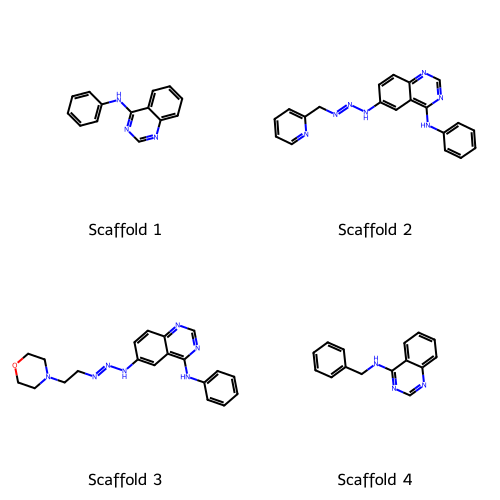

Total active EGFR molecules: 12
Number of unique scaffolds: 4
Scaffold 1: c1ccc(Nc2ncnc3ccccc23)cc1
Scaffold 2: c1ccc(Nc2ncnc3ccc(N/N=N/Cc4ccccn4)cc23)cc1
Scaffold 3: c1ccc(Nc2ncnc3ccc(N/N=N/CCN4CCOCC4)cc23)cc1
Scaffold 4: c1ccc(CNc2ncnc3ccccc23)cc1


In [35]:

from rdkit import Chem
from rdkit.Chem import Draw

# Step 1: Get unique scaffold SMILES
# from our 12 active EGFR molecules
unique_scaffold_smiles = (
    egfr_active["Scaffold"]
    .dropna()
    .unique()
    .tolist()
)

# Step 2: Convert scaffold SMILES
# into RDKit molecular objects
scaffold_mols = [
    Chem.MolFromSmiles(smi)
    for smi in unique_scaffold_smiles
]

# Step 3: Create labels for each scaffold
labels = [
    f"Scaffold {i+1}"
    for i in range(len(scaffold_mols))
]

# Step 4: Draw the four unique scaffolds
img = Draw.MolsToGridImage(
    scaffold_mols,
    molsPerRow=2,
    subImgSize=(250, 250),
    legends=labels
)

# Step 5: Display the scaffold structures
display(img)

# Step 6: Print scaffold information
print("Total active EGFR molecules:", len(egfr_active))
print("Number of unique scaffolds:", len(unique_scaffold_smiles))

# Step 7: Display each scaffold SMILES
for i, smi in enumerate(unique_scaffold_smiles, start=1):
    print(f"Scaffold {i}: {smi}")


2.27 — Analyze IC50 values by scaffold

In [36]:

# Group active EGFR compounds by their scaffold
scaffold_activity = (
    egfr_active
    .groupby("Scaffold")
    .agg(
        Molecule_Count=("molecule_chembl_id", "nunique"),
        Minimum_IC50=("IC50_nM", "min"),
        Median_IC50=("IC50_nM", "median"),
        Maximum_IC50=("IC50_nM", "max")
    )
    .reset_index()
)

# Sort by the number of molecules
scaffold_activity = scaffold_activity.sort_values(
    "Molecule_Count",
    ascending=False
)

display(scaffold_activity)

print(
    "Scaffold groups analyzed:",
    len(scaffold_activity)
)


,Scaffold,Molecule_Count,Minimum_IC50,Median_IC50,Maximum_IC50
3,c1ccc(Nc2ncnc3ccccc23)cc1,8,11.0,72.0,1000.0
0,c1ccc(CNc2ncnc3ccccc23)cc1,2,482.0,495.0,508.0
1,c1ccc(Nc2ncnc3ccc(N/N=N/CCN4CCOCC4)cc23)cc1,1,64.0,64.0,64.0
2,c1ccc(Nc2ncnc3ccc(N/N=N/Cc4ccccn4)cc23)cc1,1,238.0,238.0,238.0


Scaffold groups analyzed: 4


2.28 — Visualize IC50 Distribution by Scaffold

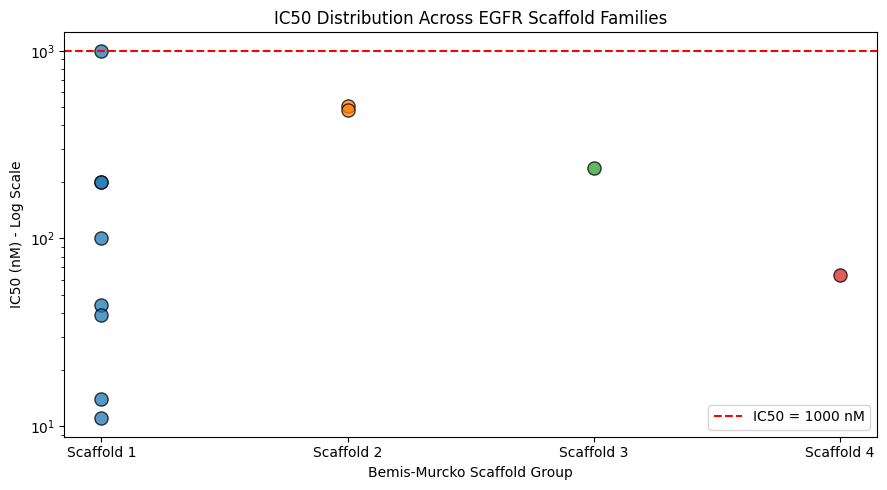

In [38]:

import matplotlib.pyplot as plt
import pandas as pd

# Assign scaffold group numbers by frequency
scaffold_order = scaffold_counts["Scaffold"].tolist()

scaffold_labels = {
    scaffold: f"Scaffold {i+1}"
    for i, scaffold in enumerate(scaffold_order)
}

# Prepare plotting data
plot_df = egfr_active.copy()

plot_df["Scaffold_Group"] = (
    plot_df["Scaffold"].map(scaffold_labels)
)

# Create scatter plot
plt.figure(figsize=(9, 5))

for i, scaffold in enumerate(scaffold_order):
    subset = plot_df[
        plot_df["Scaffold"] == scaffold
    ]

    plt.scatter(
        [i+1] * len(subset),
        subset["IC50_nM"],
        s=90,
        alpha=0.75,
        edgecolors="black"
    )

# Use logarithmic axis
plt.yscale("log")

# Display scaffold labels
plt.xticks(
    range(1, len(scaffold_order)+1),
    [f"Scaffold {i+1}" for i in range(len(scaffold_order))]
)

# Show our activity threshold
plt.axhline(
    y=1000,
    color="red",
    linestyle="--",
    label="IC50 = 1000 nM"
)

plt.xlabel("Bemis-Murcko Scaffold Group")
plt.ylabel("IC50 (nM) - Log Scale")

plt.title(
    "IC50 Distribution Across EGFR Scaffold Families"
)

plt.legend()
plt.tight_layout()
plt.show()


2.29 — Save the EGFR scaffold-analysis dataset

In [39]:

# Select columns for our final dataset
export_columns = [
    "activity_id",
    "assay_chembl_id",
    "molecule_chembl_id",
    "canonical_smiles",
    "IC50_nM",
    "Scaffold"
]

# Create export DataFrame
egfr_export = egfr_active[export_columns].copy()

# Sort by IC50
egfr_export = egfr_export.sort_values(
    "IC50_nM"
)

# Save experimental data
egfr_export.to_csv(
    "Week_01_Day_02_EGFR_Active_Compounds.csv",
    index=False
)

# Save scaffold frequency summary
scaffold_counts.to_csv(
    "Week_01_Day_02_Scaffold_Frequency.csv",
    index=False
)

# Save scaffold activity summary
scaffold_activity.to_csv(
    "Week_01_Day_02_Scaffold_Activity.csv",
    index=False
)

print("Files saved successfully!")

print("Active compounds:", len(egfr_export))
print("Unique molecules:",
      egfr_export["molecule_chembl_id"].nunique())

print("Unique scaffolds:",
      egfr_export["Scaffold"].nunique())

print("Files created:")
print("1. Week_01_Day_02_EGFR_Active_Compounds.csv")
print("2. Week_01_Day_02_Scaffold_Frequency.csv")
print("3. Week_01_Day_02_Scaffold_Activity.csv")


Files saved successfully!
Active compounds: 12
Unique molecules: 12
Unique scaffolds: 4
Files created:
1. Week_01_Day_02_EGFR_Active_Compounds.csv
2. Week_01_Day_02_Scaffold_Frequency.csv
3. Week_01_Day_02_Scaffold_Activity.csv


2.30 — Create a reproducible Python environment

In [40]:
#Record Python Environment and Package Versions
import sys
import rdkit
import pandas as pd
import numpy as np
import matplotlib

# Display Python and package versions
print("Python:", sys.version.split()[0])
print("RDKit:", rdkit.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

# Save a pip environment snapshot
import subprocess

with open("Week_01_Day_02_requirements.txt", "w") as f:
    subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        stdout=f,
        check=True
    )

print("\nEnvironment snapshot saved!")
print("File: Week_01_Day_02_requirements.txt")


Python: 3.13.16
RDKit: 2026.09.1
Pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0

Environment snapshot saved!
File: Week_01_Day_02_requirements.txt


2.31 — Create a project-specific requirements file

In [41]:

import importlib.metadata as metadata
import sys

# Packages directly used in our project
packages = {
    "rdkit": "rdkit",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "chembl_webresource_client": "chembl_webresource_client"
}

# Create a smaller requirements file
with open("requirements.txt", "w") as f:
    for package_name, distribution_name in packages.items():
        version = metadata.version(distribution_name)
        f.write(f"{package_name}=={version}\n")

print("Python version:", sys.version.split()[0])
print("\nProject requirements:")

with open("requirements.txt", "r") as f:
    print(f.read())


Python version: 3.13.16

Project requirements:
rdkit==2026.9.1
pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0
chembl_webresource_client==0.10.9

